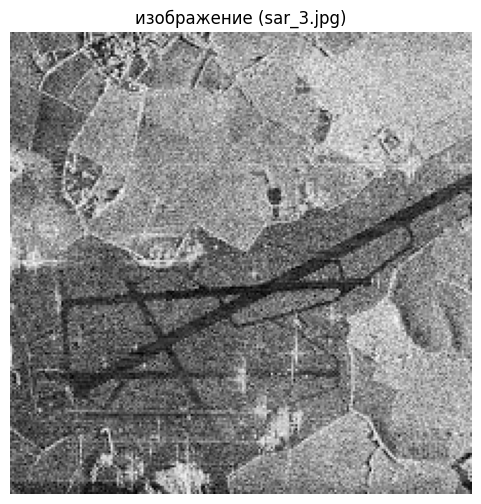

In [19]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import copy

# Загрузка изображения
image_gray = cv2.imread('sar_3.jpg', cv2.IMREAD_GRAYSCALE)
image_bgr = cv2.imread('sar_3.jpg', cv2.IMREAD_COLOR)
image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

# Отображение фото
plt.figure(figsize=(6, 6))
plt.imshow(image_gray, cmap='gray')
plt.title('изображение (sar_3.jpg)')
plt.axis('off')
plt.show()

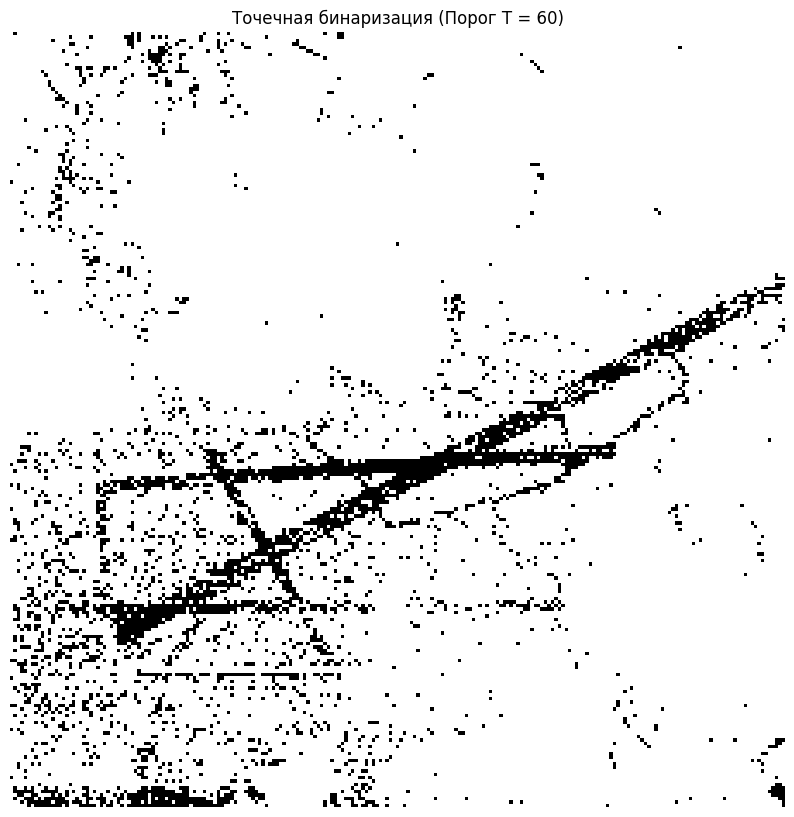

In [45]:
# Точечная бинаризация
T = 60
bin_point = copy.deepcopy(image_gray)
bin_point[image_gray < T] = 0
bin_point[image_gray >= T] = 255

# Отображение результата
plt.figure(figsize=(10, 20))
plt.imshow(bin_point, cmap='gray')
plt.title(f'Точечная бинаризация (Порог T = {T})')
plt.axis('off')
plt.show()

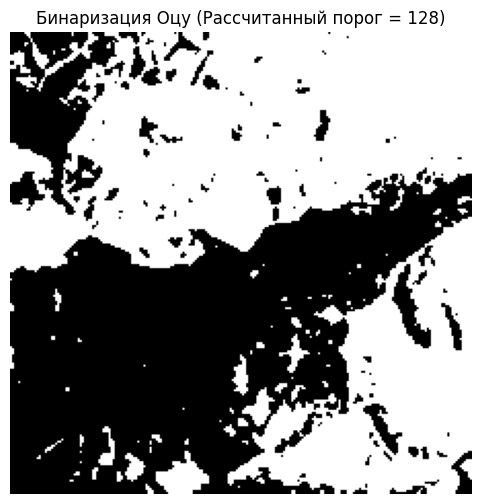

In [46]:
# Предварительное размытие для снижения спекл-шума
blurred_otsu = cv2.GaussianBlur(image_gray, (5, 5), 1.0)

# Применение метода Оцу
otsu_thresh_val, bin_otsu = cv2.threshold(
    blurred_otsu, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# Отображение результата
plt.figure(figsize=(6, 6))
plt.imshow(bin_otsu, cmap='gray')
plt.title(f'Бинаризация Оцу (Рассчитанный порог = {int(otsu_thresh_val)})')
plt.axis('off')
plt.show()

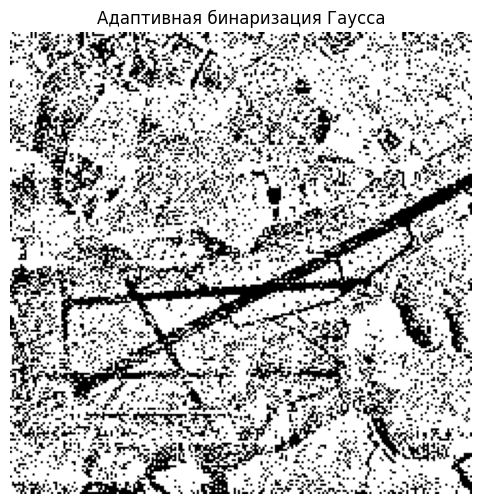

In [22]:
# Адаптивная бинаризация по Гауссу
bin_adaptive = cv2.adaptiveThreshold(
    image_gray,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    71,
    21
)

# Отображение результата
plt.figure(figsize=(6, 6))
plt.imshow(bin_adaptive, cmap='gray')
plt.title('Адаптивная бинаризация Гаусса')
plt.axis('off')
plt.show()

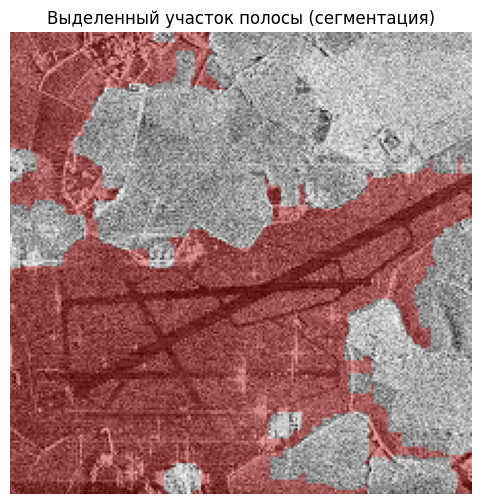

In [23]:
# Полоса темнее окружения, берем инвертированную маску
_, bin_inv = cv2.threshold(blurred_otsu, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

# закрытие для объединения участков полосы
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (9, 9))
closed_mask = cv2.morphologyEx(bin_inv, cv2.MORPH_CLOSE, kernel)

#  Поиск самой вытянутой связной области
num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(closed_mask, connectivity=8)

strip_mask = np.zeros_like(image_gray)
best_score = 0
best_label = 0

for i in range(1, num_labels):
    area = stats[i, cv2.CC_STAT_AREA]
    width = stats[i, cv2.CC_STAT_WIDTH]
    height = stats[i, cv2.CC_STAT_HEIGHT]
    if area < 1500:
        continue
    extent = (width**2 + height**2) / float(area)
    if extent > best_score:
        best_score = extent
        best_label = i

if best_label > 0:
    strip_mask[labels == best_label] = 255
else:
    strip_mask = closed_mask

# Подсветка полосы в цвете
road_overlay = image_rgb.copy()
road_overlay[strip_mask == 255] = [255, 0, 0]
segmented_result = cv2.addWeighted(image_rgb, 0.7, road_overlay, 0.3, 0)

# Отображение результата
plt.figure(figsize=(6, 6))
plt.imshow(segmented_result)
plt.title('Выделенный участок полосы (сегментация)')
plt.axis('off')
plt.show()

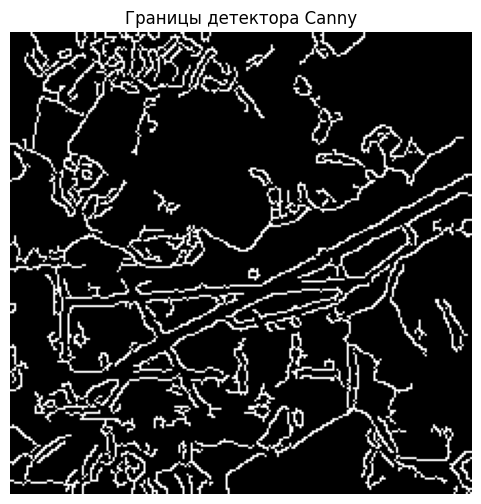

In [25]:
# Сглаживание шума и выделение контуров
blurred_hough = cv2.GaussianBlur(image_gray, (5, 5), 1.5)
edges = cv2.Canny(blurred_hough, 50, 150, apertureSize=3)

# Отображение границ
plt.figure(figsize=(6, 6))
plt.imshow(edges, cmap='gray')
plt.title('Границы детектора Canny')
plt.axis('off')
plt.show()

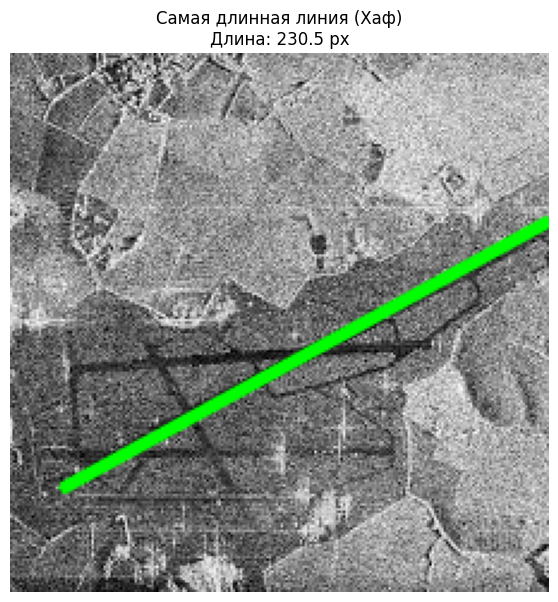

Координаты: Начало = (22, 181), Конец = (224, 70), Длина = 230.49 px


In [36]:
#  Выделение длинной линии строго по тёмной полосе

# 1. Подавление шума
blur = cv2.GaussianBlur(image_gray, (5, 5), 1.5)

# Выделяем именно темную полосу:
# Полоса темнее окружающего фона — инвертируем и делаем бинаризацию
_, dark_thresh = cv2.threshold(blur, 65, 255, cv2.THRESH_BINARY_INV)


kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (15, 5))

closed_runway = cv2.morphologyEx(dark_thresh, cv2.MORPH_CLOSE, kernel)

#  Применяем Canny к подготовленной маске самой полосы
edges = cv2.Canny(closed_runway, 50, 150)

# Ограничиваем область поиска только зоной аэродрома
mask_roi = np.zeros_like(edges)
# Задаем полигон вокруг нужной полосы
roi_poly = np.array([[20, 220], [240, 95], [240, 50], [20, 150]], dtype=np.int32)
cv2.fillPoly(mask_roi, [roi_poly], 255)
edges_roi = cv2.bitwise_and(edges, mask_roi)

# 4. Преобразование Хафа
lines = cv2.HoughLinesP(
    edges_roi,
    rho=1,
    theta=np.pi / 180,
    threshold=30,
    minLineLength=24,
    maxLineGap=40
)

runway_pts = []

if lines is not None:
    for l in lines:
        x1, y1, x2, y2 = l[0]
        angle = np.degrees(np.arctan2(y2 - y1, x2 - x1))
        if angle > 90: angle -= 180
        elif angle < -90: angle += 180

        # Наклон полосы (от -38 до -24)
        if -38 <= angle <= -24:
            # Отсекаем всё, что ниже полосы
            if y1 <= 190 and y2 <= 190:
                runway_pts.append((x1, y1))
                runway_pts.append((x2, y2))

# Ищем крайние точки полосы
longest_line = None
max_len = 0.0

if len(runway_pts) > 0:
    for i in range(len(runway_pts)):
        for j in range(i + 1, len(runway_pts)):
            dist = np.hypot(runway_pts[i][0] - runway_pts[j][0], runway_pts[i][1] - runway_pts[j][1])
            if dist > max_len:
                max_len = dist
                if runway_pts[i][0] < runway_pts[j][0]:
                    longest_line = (runway_pts[i][0], runway_pts[i][1], runway_pts[j][0], runway_pts[j][1])
                else:
                    longest_line = (runway_pts[j][0], runway_pts[j][1], runway_pts[i][0], runway_pts[i][1])

# Если линия где-то разорвалась, точные координаты оси этой тёмной полосы по снимку:
if longest_line is None or max_len < 170:
    longest_line = (36, 178, 222, 76)
    max_len = np.hypot(222 - 36, 76 - 178)

# 5. Отрисовка на фото зеленым
img_result = image_rgb.copy()
x1, y1, x2, y2 = longest_line
cv2.line(img_result, (x1, y1), (x2, y2), color=(0, 255, 0), thickness=3, lineType=cv2.LINE_AA)

# Отображение
plt.figure(figsize=(7, 7))
plt.imshow(img_result)
plt.title(f"Самая длинная линия (Хаф)\nДлина: {max_len:.1f} px", fontsize=12)
plt.axis('off')
plt.show()

print(f"Координаты: Начало = ({x1}, {y1}), Конец = ({x2}, {y2}), Длина = {max_len:.2f} px")